# CIC-IDS2017 vs CSE-CIC-IDS2018: how much of the random-split score survives?

This notebook only reads the files written by the four scripts (`results/*.csv`,
`figures/*.png`). It does not train anything. Run `01` to `04` first.

In [1]:
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

## 1. Data after cleaning

Row counts after each cleaning step, and the composition of the 2018 sample.
Labels with fewer than 20k cleaned rows are kept whole, the rest are sampled at
about 11%.

In [2]:
pd.read_csv("results/prep_counts.csv").convert_dtypes()

,dataset,raw,after_drop_header_rows,after_drop_nan_inf,after_dedup
0,CIC-IDS2017,2830743,2830743,2827876,2233164
1,CSE-CIC-IDS2018,16233002,16232943,16137183,10851047
2,CSE-CIC-IDS2018 sample,<NA>,<NA>,<NA>,1199999


In [3]:
sample = pd.read_csv("results/sample_2018_counts.csv")
sample.groupby("family")[["cleaned", "sampled"]].sum().sort_values("sampled", ascending=False)

,cleaned,sampled
family,,
Benign,9525202,1043518
DDoS,775955,86549
DoS,196568,30406
Bot,144535,15834
Infiltration,113819,12469
Brute force,94101,10356
Web attack,867,867


## 2. Main table

Mean and standard deviation over 3 seeds. In A and B it is the same fitted
model each time: trained on 80% of 2017, scored on the other 20% (A) and on the
2018 sample (B). C trains on the 2018 sample and scores all of 2017. The
reference row is a random 80/20 split inside the 2018 sample, so C has an
in-domain number to compare against.

In [4]:
main = pd.read_csv("results/main_table.csv")
show = main.copy()
for m in ["macro_f1", "attack_recall", "benign_fpr", "auroc"]:
    show[m] = show[f"{m}_mean"].map("{:.3f}".format) + " Â± " + show[f"{m}_std"].map("{:.3f}".format)
show[["experiment", "model", "macro_f1", "attack_recall", "benign_fpr", "auroc"]]

,experiment,model,macro_f1,attack_recall,benign_fpr,auroc
0,A: 2017 random split,LightGBM,0.999 Â± 0.000,0.998 Â± 0.000,0.001 Â± 0.000,1.000 Â± 0.000
1,A: 2017 random split,MLP,0.996 Â± 0.000,0.992 Â± 0.001,0.001 Â± 0.000,1.000 Â± 0.000
2,A: 2017 random split,RF,0.998 Â± 0.000,0.995 Â± 0.000,0.000 Â± 0.000,1.000 Â± 0.000
3,"B: train 2017, test 2018",LightGBM,0.504 Â± 0.003,0.039 Â± 0.003,0.001 Â± 0.000,0.767 Â± 0.014
4,"B: train 2017, test 2018",MLP,0.536 Â± 0.003,0.080 Â± 0.006,0.009 Â± 0.006,0.518 Â± 0.005
5,"B: train 2017, test 2018",RF,0.520 Â± 0.002,0.057 Â± 0.002,0.001 Â± 0.000,0.828 Â± 0.013
6,"C: train 2018, test 2017",LightGBM,0.670 Â± 0.026,0.261 Â± 0.039,0.005 Â± 0.001,0.854 Â± 0.087
7,"C: train 2018, test 2017",MLP,0.528 Â± 0.143,0.310 Â± 0.203,0.241 Â± 0.108,0.543 Â± 0.129
8,"C: train 2018, test 2017",RF,0.690 Â± 0.053,0.309 Â± 0.088,0.012 Â± 0.001,0.825 Â± 0.003
9,Ref: 2018 random split,LightGBM,0.976 Â± 0.000,0.921 Â± 0.000,0.001 Â± 0.000,0.990 Â± 0.000


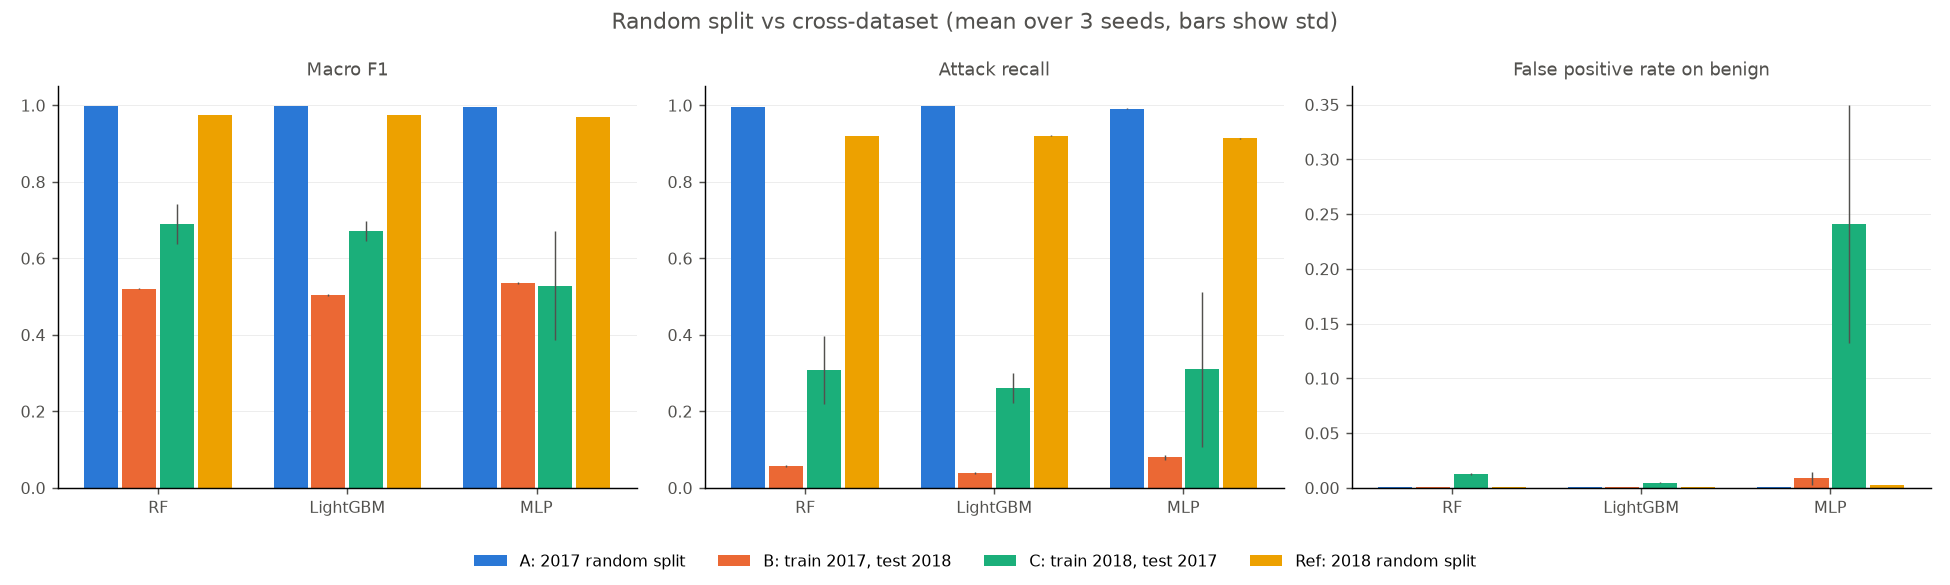

In [5]:
display(Image("figures/random_vs_cross.png"))

What the table says:

- On the 2017 random split all three models are at 0.996 to 0.999 macro F1.
  That is the number papers usually report.
- Moving the same models to 2018 (B), macro F1 drops to 0.50 to 0.54 and
  attack recall to 4 to 8%. The false positive rate stays below 1%, so the
  models aren't flagging everything; they let almost every 2018 attack through
  as benign.
- AUROC in B is 0.77 (LightGBM) and 0.83 (RF), so the tree models still rank
  2018 attacks somewhat above benign; the 0.5 threshold from 2017 just sits in
  the wrong place. The MLP's 0.52 is close to chance.
- The other direction (C) is a little better for the tree models (macro F1
  0.67 to 0.69, recall 26 to 31%) but nowhere near the 0.97 that the same models
  get inside 2018. The MLP is unstable in C: its false positive rate swings
  from 12% to 31% between seeds.

In [6]:
diff = main.pivot(index="model", columns="experiment", values="macro_f1_mean")
pd.DataFrame({
    "A minus B": diff["A: 2017 random split"] - diff["B: train 2017, test 2018"],
    "Ref minus C": diff["Ref: 2018 random split"] - diff["C: train 2018, test 2017"],
}).round(3)

,A minus B,Ref minus C
model,,
LightGBM,0.495,0.305
MLP,0.460,0.441
RF,0.478,0.284


## 3. Per-family recall

Only for the six families that exist in both datasets. Port scan and
Heartbleed are 2017-only and are left out here (they still count in the overall
attack recall of A and C).

In [7]:
fam = pd.read_csv("results/per_family_recall.csv")
fam.pivot_table(index=["experiment", "model"], columns="family", values="recall_mean").round(3)

family                               Bot  Brute force   DDoS    DoS  Infiltration  Web attack
experiment               model                                                               
A: 2017 random split     LightGBM  0.656        0.998  1.000  0.999         0.667       0.986
                         MLP       0.598        0.969  0.999  0.992         0.095       0.918
                         RF        0.624        0.990  1.000  0.996         0.667       0.954
B: train 2017, test 2018 LightGBM  0.000        0.000  0.004  0.191         0.000       0.003
                         MLP       0.000        0.002  0.013  0.371         0.010       0.000
                         RF        0.000        0.000  0.004  0.282         0.000       0.001
C: train 2018, test 2017 LightGBM  0.000        0.002  0.182  0.332         0.018       0.018
                         MLP       0.002        0.005  0.088  0.476         0.167       0.081
                         RF        0.000        0.138  0.006  0.524         0.000       0.009
Ref: 2018 random split   LightGBM  0.994        1.000  1.000  0.998         0.037       0.796
                         MLP       0.986        0.997  0.993  0.998         0.032       0.445
                         RF        0.992        0.999  0.997  1.000         0.041       0.699

In [8]:
fam.groupby(["experiment", "family"])["n"].first().unstack()

family,Bot,Brute force,DDoS,DoS,Infiltration,Web attack
experiment,,,,,,
A: 2017 random split,288,1830,25603,38749,7,428
"B: train 2017, test 2018",15834,10356,86549,30406,12469,867
"C: train 2018, test 2017",1437,9150,128014,193745,36,2143
Ref: 2018 random split,3167,2071,17310,6081,2494,173


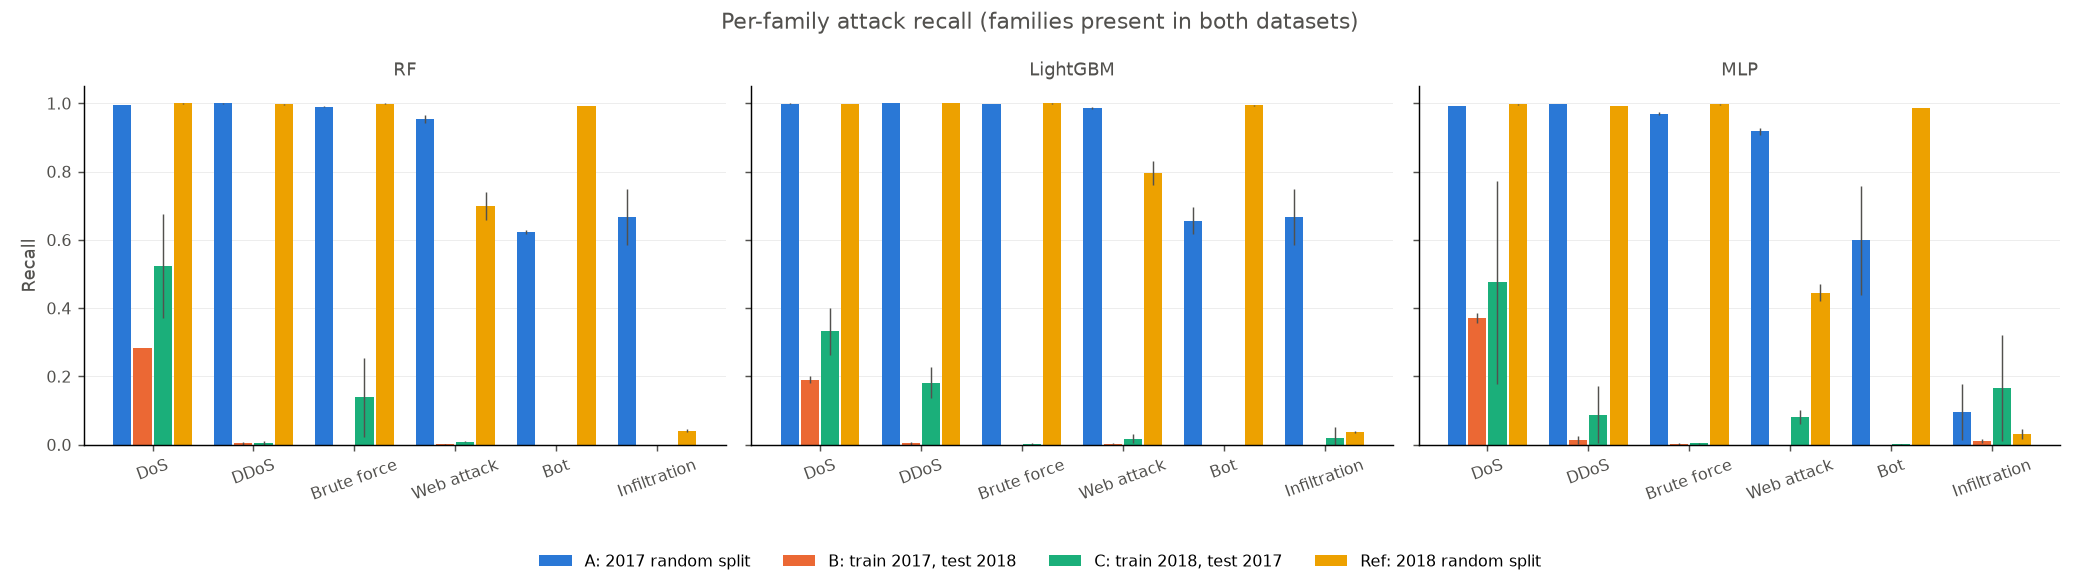

In [9]:
display(Image("figures/per_family_recall.png"))

- Bot, brute force and web attack transfer at about zero in both directions,
  even though each is near-perfect inside its own dataset (except 2017 Bot,
  which is only around 60% even in-domain).
- DoS is the only family that partly carries over: 19 to 37% recall in B and
  33 to 52% in C.
- DDoS doesn't transfer although both years include LOIC.
- Infiltration is hard everywhere. 2017 has 36 rows in total (7 in each test
  split), and 2018 Infiltration is caught about 4% of the time even inside 2018,
  so as labelled it looks like benign traffic.

## 4. Which features shift

KS statistic between 2017 and 2018 for the 10 features with the highest
LightGBM gain (models trained on 2017, gain averaged over the 3 seeds),
computed on all rows, on benign rows only and on attack rows only.

In [10]:
pd.read_csv("results/feature_shift.csv").round(3)

,feature,ks_all,ks_benign,ks_attack,median_benign_2017,median_benign_2018
0,Bwd Packet Length Std,0.219,0.291,0.724,0.000,110.665
1,Bwd Packet Length Min,0.283,0.342,0.030,6.000,0.000
2,Bwd Packets/s,0.181,0.244,0.285,24.082,3.464
3,Init_Win_bytes_backward,0.192,0.246,0.698,-1.000,149.000
4,Average Packet Size,0.171,0.152,0.721,84.500,96.000
5,Fwd Header Length,0.217,0.244,0.533,64.000,92.000
6,Init_Win_bytes_forward,0.295,0.265,0.515,60.000,8192.000
7,Total Fwd Packets,0.201,0.287,0.552,2.000,4.000
8,FIN Flag Count,0.031,0.006,0.174,0.000,0.000
9,Fwd Packet Length Max,0.219,0.276,0.295,44.000,140.000


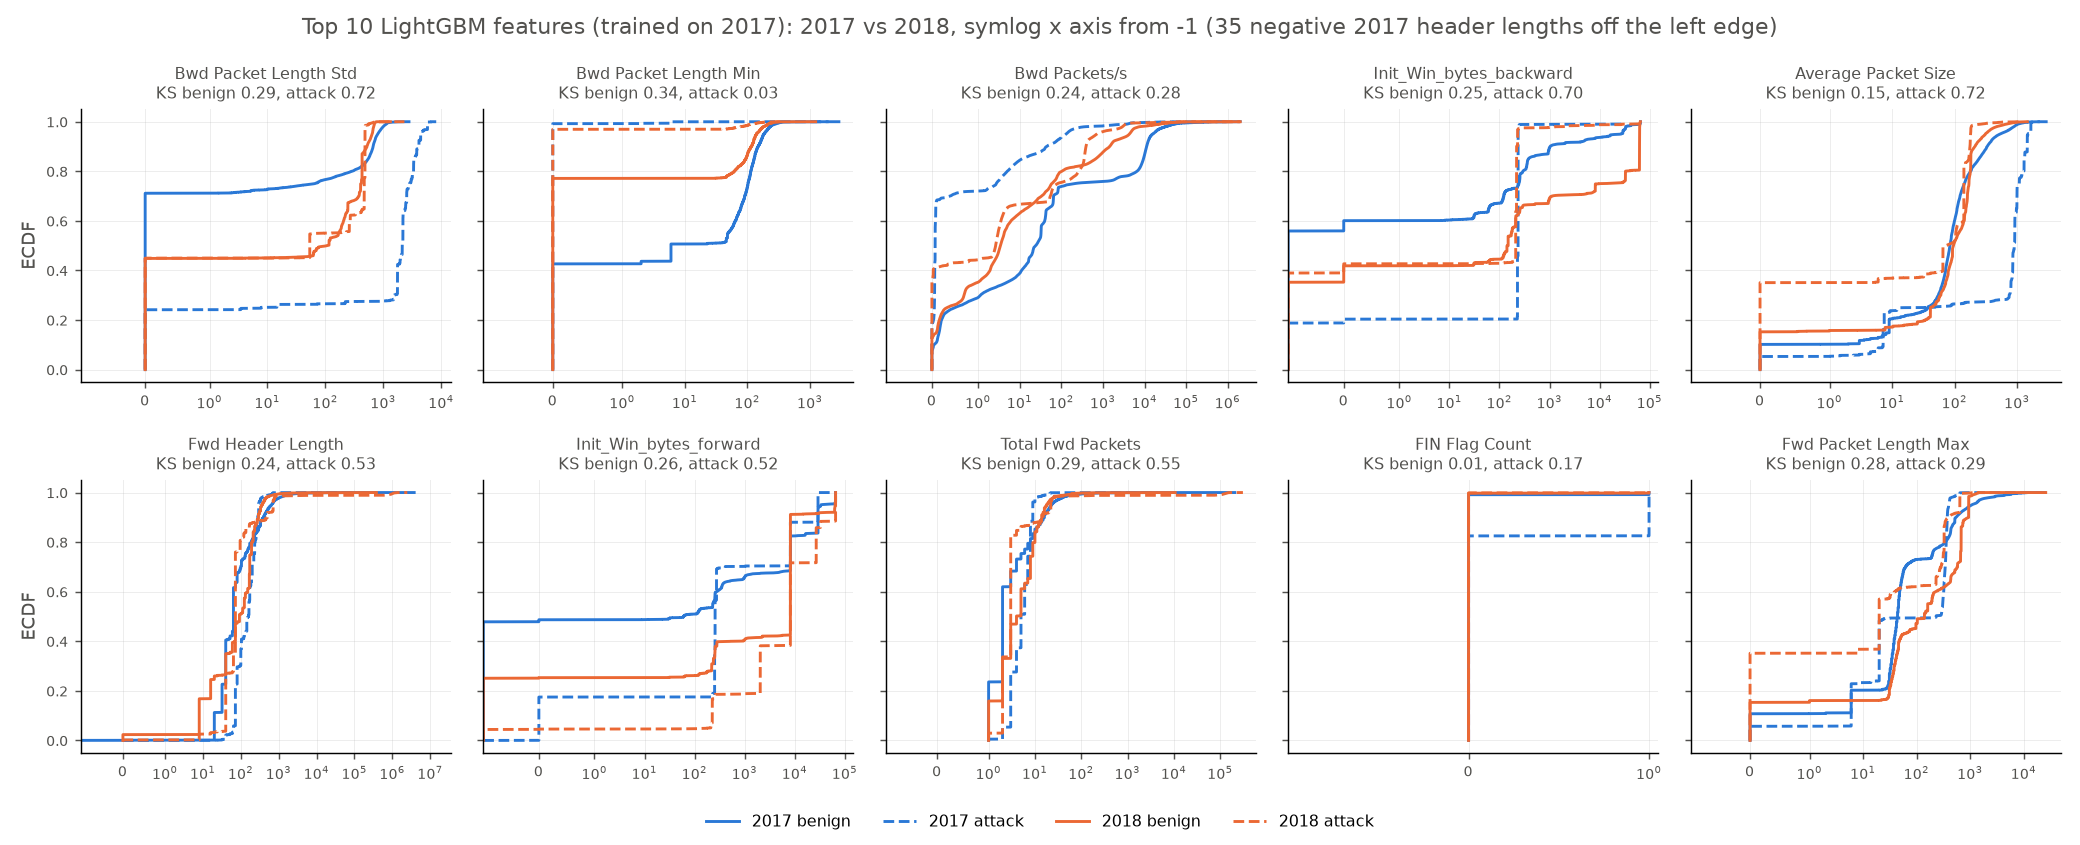

In [11]:
display(Image("figures/feature_shift.png"))

- Nine of the ten features shift by a KS of 0.15 to 0.34 on benign traffic
  alone, so the benign baseline itself moved between the two captures. The TCP
  initial window fields and backward packet lengths are the clearest examples.
- On attack traffic three features shift by KS 0.70 to 0.72 (backward packet
  length std, initial backward window, average packet size).
- The models lean on exactly these features, so the drop in B is what you
  would expect: the decision boundary learned on 2017 values doesn't line up
  with where 2018 traffic sits.
- The benign KS uses the plain random sample of benign 2018 rows, so it isn't
  distorted by the sampling. The attack KS is affected, because rare labels
  were kept whole in the 2018 sample.

## 5. Note on LightGBM

In the first full run LightGBM diverged during training (raw scores near 1e7,
training AUROC falling to 0.84 by round 300). I capped leaf outputs with
`max_delta_step=1.0`, chosen on training data only, and re-ran everything. The
first run's per-seed numbers are kept in `results/first_run_lgbm_diverged_runs.csv`.
RF and MLP numbers matched between the two runs.

In [12]:
first = pd.read_csv("results/first_run_lgbm_diverged_runs.csv")
first[first["model"] == "LightGBM"].groupby("experiment")[["macro_f1", "attack_recall", "benign_fpr", "auroc"]].mean().round(3)

,macro_f1,attack_recall,benign_fpr,auroc
experiment,,,,
A: 2017 random split,0.942,0.913,0.020,0.933
"B: train 2017, test 2018",0.599,0.233,0.063,0.705
"C: train 2018, test 2017",0.804,0.588,0.033,0.854
Ref: 2018 random split,0.975,0.921,0.001,0.990
